# Real-World Dataset Analysis Project
Breast Cancer Wisconsin (Diagnostic) dataset: exploration, cleaning, exploratory data analysis, visualization and interpretation.

Run the cells from top to bottom (Kernel > Restart & Run All). Charts are saved in the charts/ folder.

## Step 1: Import libraries and settings

In [1]:
%matplotlib inline
import os
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs("charts", exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 95)
pd.set_option("display.max_columns", 20)
PAL = {"Benign": "#2E75B6", "Malignant": "#C00000"}

print("Python     :", platform.python_version())
print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)
print("seaborn    :", sns.__version__)

Python     : 3.12.3
pandas     : 3.0.2
numpy      : 2.4.4
matplotlib : 3.10.8
seaborn    : 0.13.2


## Step 2: Load the real-world dataset
The Breast Cancer Wisconsin (Diagnostic) dataset from the UCI Machine Learning Repository. A copy of it ships inside scikit-learn, so it loads without any download. The columns are renamed to the UCI naming style and the numeric target is converted into readable labels.

In [2]:
from sklearn.datasets import load_breast_cancer

raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()

def rename(col):
    col = col.replace(" ", "_")
    if col.startswith("mean_"):
        return col[5:] + "_mean"
    if col.startswith("worst_"):
        return col[6:] + "_worst"
    if col.endswith("_error"):
        return col[:-6] + "_se"
    return col

df = df.rename(columns=rename)

# in the original data target 0 = malignant and 1 = benign (check it, do not assume)
print("Target names in the source:", [str(n) for n in raw.target_names])
df["diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})
df = df.drop(columns="target")

base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]
mean_cols = [b + "_mean" for b in base]
feature_cols = [c for c in df.columns if c != "diagnosis"]

df.to_csv("breast_cancer_wisconsin.csv", index=False)
print("Saved breast_cancer_wisconsin.csv:", df.shape[0], "rows x", df.shape[1], "columns")
print("Number of numeric features:", len(feature_cols))

Target names in the source: ['malignant', 'benign']
Saved breast_cancer_wisconsin.csv: 569 rows x 31 columns
Number of numeric features: 30


## Part A: Explore the dataset
### A1. Structure, data types and summary statistics

In [3]:
print("Shape (rows, columns):", df.shape)
print()
print(df[["radius_mean", "texture_mean", "perimeter_mean", "area_mean", "smoothness_mean", "diagnosis"]].head())
print()
df.info()

Shape (rows, columns): (569, 31)

   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  diagnosis
0        17.99         10.38          122.80     1001.0          0.11840  Malignant
1        20.57         17.77          132.90     1326.0          0.08474  Malignant
2        19.69         21.25          130.00     1203.0          0.10960  Malignant
3        11.42         20.38           77.58      386.1          0.14250  Malignant
4        20.29         14.34          135.10     1297.0          0.10030  Malignant

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   radius_mean              569 non-null    float64
 1   texture_mean             569 non-null    float64
 2   perimeter_mean           569 non-null    float64
 3   area_mean                569 non-null    float64
 4   smoothness_mean          569 non-null 

### A2. Distribution summary, missing values, duplicates and class balance

In [4]:
print("Summary statistics of the 10 'mean' features:")
print(df[mean_cols].describe().T.round(3))

print("\nMissing values in the whole dataset:", int(df.isna().sum().sum()))
print("Fully duplicated rows              :", int(df.duplicated().sum()))
print("Duplicates considering features only:", int(df[feature_cols].duplicated().sum()))

print("\nClass balance:")
balance = df["diagnosis"].value_counts()
print(pd.DataFrame({"count": balance, "percent": (balance / len(df) * 100).round(1)}))

Summary statistics of the 10 'mean' features:
                        count     mean      std      min      25%      50%      75%       max
radius_mean             569.0   14.127    3.524    6.981   11.700   13.370   15.780    28.110
texture_mean            569.0   19.290    4.301    9.710   16.170   18.840   21.800    39.280
perimeter_mean          569.0   91.969   24.299   43.790   75.170   86.240  104.100   188.500
area_mean               569.0  654.889  351.914  143.500  420.300  551.100  782.700  2501.000
smoothness_mean         569.0    0.096    0.014    0.053    0.086    0.096    0.105     0.163
compactness_mean        569.0    0.104    0.053    0.019    0.065    0.093    0.130     0.345
concavity_mean          569.0    0.089    0.080    0.000    0.030    0.062    0.131     0.427
concave_points_mean     569.0    0.049    0.039    0.000    0.020    0.034    0.074     0.201
symmetry_mean           569.0    0.181    0.027    0.106    0.162    0.179    0.196     0.304
fractal_dimens

## Part B: Clean and preprocess the data
### B1. Validity and consistency checks

In [5]:
# 1) Impossible values: negative numbers are not allowed for any measurement
print("Negative values in any feature:", int((df[feature_cols] < 0).sum().sum()))

# 2) Zero values: are they errors or real measurements?
zeros = (df[feature_cols] == 0).sum()
print("\nColumns that contain zeros:")
print(zeros[zeros > 0])

# 3) Range check for smoothness-type features (must lie between 0 and 1)
print("\nMax smoothness_mean:", df["smoothness_mean"].max().round(3), "| max symmetry_mean:", df["symmetry_mean"].max().round(3))

# 4) Internal consistency: area should be close to pi * radius^2, perimeter close to 2 * pi * radius
ratio = df["area_mean"] / (np.pi * df["radius_mean"] ** 2)
print("\nArea / (pi x radius^2):")
print(ratio.describe().round(3))
print("Correlation perimeter vs 2 x pi x radius:",
      round(np.corrcoef(df["perimeter_mean"], 2 * np.pi * df["radius_mean"])[0, 1], 4))

# 5) Label consistency
print("\nUnique diagnosis labels:", sorted(df["diagnosis"].unique()))

Negative values in any feature: 0

Columns that contain zeros:
concavity_mean          13
concave_points_mean     13
concavity_se            13
concave_points_se       13
concavity_worst         13
concave_points_worst    13
dtype: int64

Max smoothness_mean: 0.163 | max symmetry_mean: 0.304

Area / (pi x radius^2):
count    569.000
mean       0.981
std        0.015
min        0.917
25%        0.972
50%        0.981
75%        0.988
max        1.064
dtype: float64
Correlation perimeter vs 2 x pi x radius: 0.9979

Unique diagnosis labels: ['Benign', 'Malignant']


### B2. Fix data types and add helper columns

In [6]:
df["diagnosis"] = pd.Categorical(df["diagnosis"], categories=["Benign", "Malignant"])
df["diagnosis_code"] = (df["diagnosis"] == "Malignant").astype(int)   # 1 = malignant, 0 = benign

print(df.dtypes.value_counts())
print("\nDiagnosis column:", df["diagnosis"].dtype, "| categories:", list(df["diagnosis"].cat.categories))
print("Malignant cases coded as 1:", int(df["diagnosis_code"].sum()))

float64     30
category     1
int64        1
Name: count, dtype: int64

Diagnosis column: category | categories: ['Benign', 'Malignant']
Malignant cases coded as 1: 212


### B3. Detect and treat outliers (IQR method)
A value is flagged as an outlier when it is more than 1.5 x IQR below Q1 or above Q3. The flagged rows are inspected before deciding whether to remove them.

Features with the most outliers (out of 569 rows):
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
dtype: int64

Rows with at least one outlier: 171 (30.1%)
Share of rows with an outlier, by diagnosis:
diagnosis
Benign       16.0
Malignant    53.8
dtype: float64

Spearman correlation of effect-size ranking, original vs capped: 0.969
Features shared by the two top-5 lists: 4 of 5


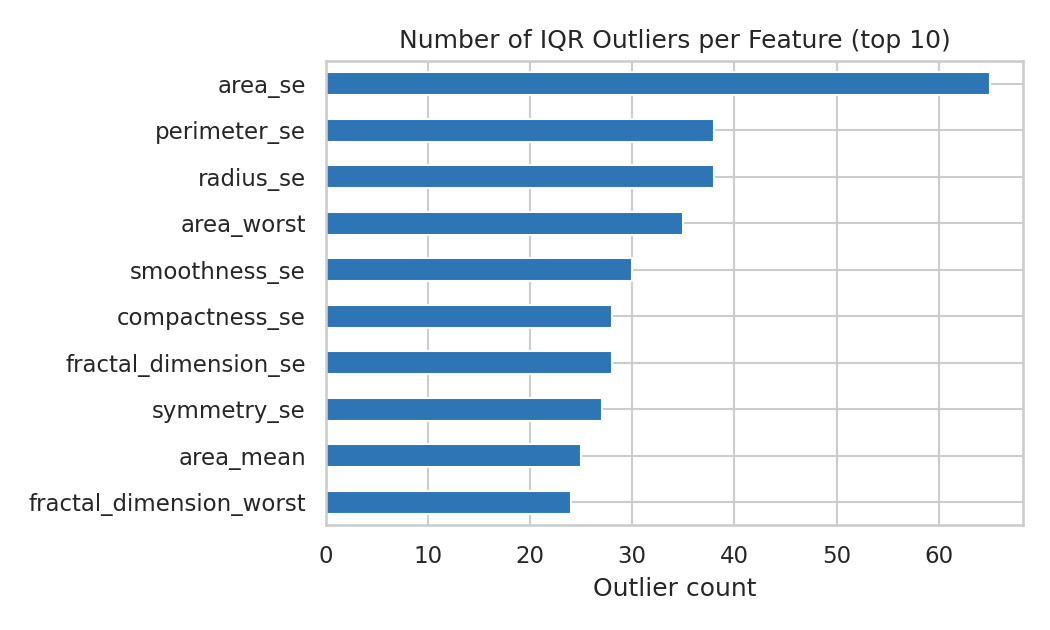

In [7]:
def cohens_d(X, y):
    """Standardised difference of means: malignant minus benign, in pooled standard deviations."""
    a, b = X[y == 1], X[y == 0]
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

X = df[feature_cols]
y = df["diagnosis_code"]

Q1, Q3 = X.quantile(0.25), X.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
is_out = (X < lower) | (X > upper)

out_counts = is_out.sum().sort_values(ascending=False)
print("Features with the most outliers (out of", len(df), "rows):")
print(out_counts.head(10))

rows_flagged = is_out.any(axis=1)
print("\nRows with at least one outlier:", int(rows_flagged.sum()), f"({rows_flagged.mean() * 100:.1f}%)")
print("Share of rows with an outlier, by diagnosis:")
print((rows_flagged.groupby(df["diagnosis"], observed=True).mean() * 100).round(1))

# Sensitivity test: cap the outliers at the IQR fences and compare the conclusions
X_cap = X.clip(lower=lower, upper=upper, axis=1)
d_raw, d_cap = cohens_d(X, y), cohens_d(X_cap, y)
rho = stats.spearmanr(d_raw.abs(), d_cap.abs())[0]
top5_raw = set(d_raw.abs().nlargest(5).index)
top5_cap = set(d_cap.abs().nlargest(5).index)
print("\nSpearman correlation of effect-size ranking, original vs capped:", round(rho, 3))
print("Features shared by the two top-5 lists:", len(top5_raw & top5_cap), "of 5")

fig, ax = plt.subplots(figsize=(7, 4.2))
out_counts.head(10).sort_values().plot(kind="barh", color="#2E75B6", ax=ax)
ax.set_title("Number of IQR Outliers per Feature (top 10)")
ax.set_xlabel("Outlier count")
plt.tight_layout()
plt.savefig("charts/01_outliers_per_feature.png", dpi=150)
plt.show()

## Part C: Exploratory Data Analysis
### C1. Compare malignant and benign tumours

In [8]:
# Mean of each 'mean' feature in the two groups
group_means = df.groupby("diagnosis", observed=True)[mean_cols].mean().T.round(3)
group_means["ratio (M/B)"] = (group_means["Malignant"] / group_means["Benign"]).round(2)
print("Average value by diagnosis:")
print(group_means)

# Effect size and a non-parametric significance test for all 30 features
rows = []
for col in feature_cols:
    m = df.loc[df["diagnosis_code"] == 1, col]
    b = df.loc[df["diagnosis_code"] == 0, col]
    p = stats.mannwhitneyu(m, b, alternative="two-sided").pvalue
    rows.append((col, cohens_d(df[col], df["diagnosis_code"]), p))
tests = pd.DataFrame(rows, columns=["feature", "cohens_d", "p_value"]).set_index("feature")
tests["abs_d"] = tests["cohens_d"].abs()
tests = tests.sort_values("abs_d", ascending=False)

alpha = 0.05 / len(tests)   # Bonferroni correction for 30 tests
print(f"\nBonferroni threshold: {alpha:.5f}")
print("Features significant after correction:", int((tests["p_value"] < alpha).sum()), "of", len(tests))
print("\nTop 10 features by effect size (Cohen's d, malignant minus benign):")
fmt = {"cohens_d": "{:.3f}".format, "p_value": "{:.2e}".format}
print(tests[["cohens_d", "p_value"]].head(10).to_string(formatters=fmt))
print("\nWeakest 3 features:")
print(tests[["cohens_d", "p_value"]].tail(3).to_string(formatters=fmt))

Average value by diagnosis:
diagnosis                Benign  Malignant  ratio (M/B)
radius_mean              12.147     17.463         1.44
texture_mean             17.915     21.605         1.21
perimeter_mean           78.075    115.365         1.48
area_mean               462.790    978.376         2.11
smoothness_mean           0.092      0.103         1.12
compactness_mean          0.080      0.145         1.81
concavity_mean            0.046      0.161         3.50
concave_points_mean       0.026      0.088         3.38
symmetry_mean             0.174      0.193         1.11
fractal_dimension_mean    0.063      0.063         1.00

Bonferroni threshold: 0.00167
Features significant after correction: 26 of 30

Top 10 features by effect size (Cohen's d, malignant minus benign):
                     cohens_d  p_value
feature                               
concave_points_worst    2.693 1.86e-77
perimeter_worst         2.598 2.58e-80
concave_points_mean     2.545 1.01e-76
radius_worst 

### C2. Correlations and skewness

In [9]:
corr = df[mean_cols].corr()

# strongly related pairs among the 'mean' features
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("r").reset_index())
pairs.columns = ["feature_1", "feature_2", "r"]
strong = pairs[pairs["r"].abs() >= 0.85].sort_values("r", ascending=False)
print("Pairs of 'mean' features with |r| >= 0.85:")
print(strong.round(3).to_string(index=False))

# correlation of every feature with being malignant
target_corr = df[feature_cols].corrwith(df["diagnosis_code"]).sort_values(ascending=False)
print("\nStrongest correlations with malignant diagnosis:")
print(target_corr.head(6).round(3))
print("\nWeakest correlations (closest to zero):")
print(target_corr.abs().sort_values().head(3).round(3))

skew = df[feature_cols].skew().sort_values(ascending=False)
print("\nMost right-skewed features:")
print(skew.head(5).round(2))
print("Features with |skew| > 1:", int((skew.abs() > 1).sum()), "of", len(skew))

Pairs of 'mean' features with |r| >= 0.85:
       feature_1           feature_2     r
     radius_mean      perimeter_mean 0.998
     radius_mean           area_mean 0.987
  perimeter_mean           area_mean 0.987
  concavity_mean concave_points_mean 0.921
compactness_mean      concavity_mean 0.883
  perimeter_mean concave_points_mean 0.851

Strongest correlations with malignant diagnosis:
concave_points_worst    0.794
perimeter_worst         0.783
concave_points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
dtype: float64

Weakest correlations (closest to zero):
symmetry_se               0.007
texture_se                0.008
fractal_dimension_mean    0.013
dtype: float64

Most right-skewed features:
area_se                 5.45
concavity_se            5.11
fractal_dimension_se    3.92
perimeter_se            3.44
radius_se               3.09
dtype: float64
Features with |skew| > 1: 22 of 30


## Part D: Data visualizations
### Chart 2: Class distribution (bar chart)

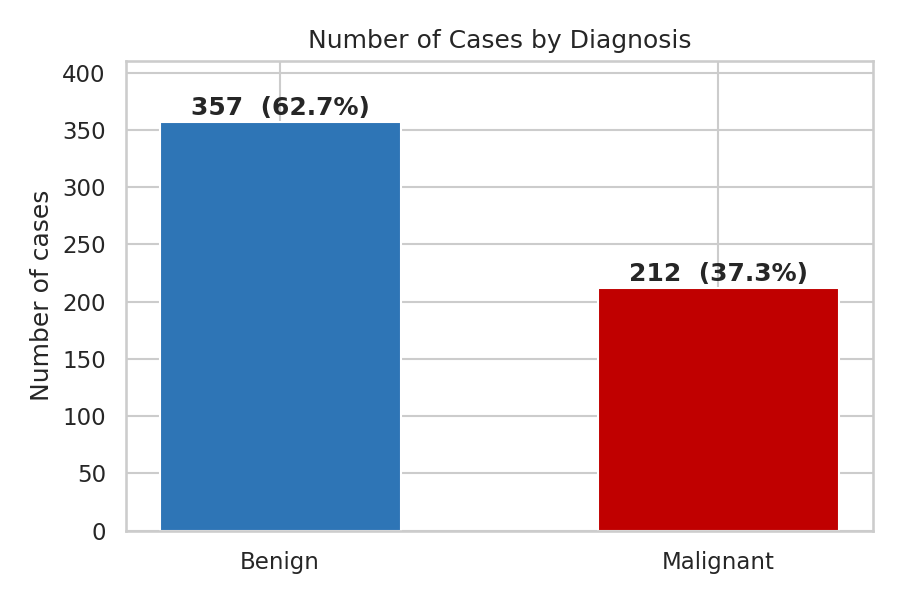

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df["diagnosis"].value_counts().reindex(["Benign", "Malignant"])
bars = ax.bar(counts.index, counts.values, color=[PAL["Benign"], PAL["Malignant"]], width=0.55)
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 6, f"{v}  ({v / len(df) * 100:.1f}%)", ha="center", fontweight="bold")
ax.set_title("Number of Cases by Diagnosis")
ax.set_ylabel("Number of cases")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig("charts/02_class_distribution.png", dpi=150)
plt.show()

### Chart 3: Feature distributions by diagnosis (histograms)

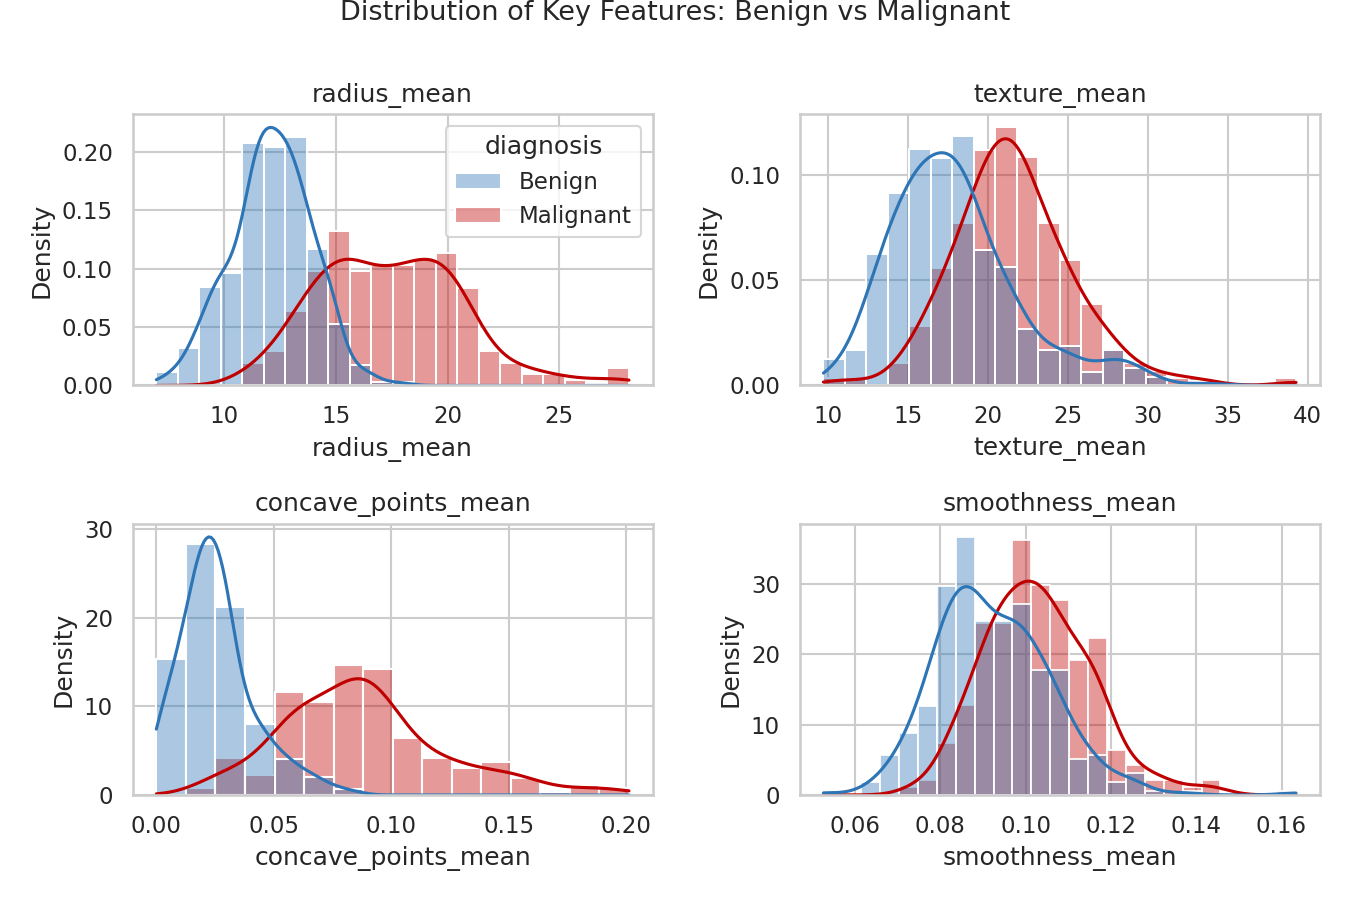

In [11]:
cols = ["radius_mean", "texture_mean", "concave_points_mean", "smoothness_mean"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(data=df, x=col, hue="diagnosis", palette=PAL, kde=True, stat="density",
                 common_norm=False, alpha=0.4, ax=ax, legend=(col == cols[0]))
    ax.set_title(col)
    ax.set_ylabel("Density")
fig.suptitle("Distribution of Key Features: Benign vs Malignant", y=1.0, fontsize=13)
plt.tight_layout()
plt.savefig("charts/03_histograms_by_diagnosis.png", dpi=150)
plt.show()

### Chart 4: Spread and outliers by diagnosis (box plots)

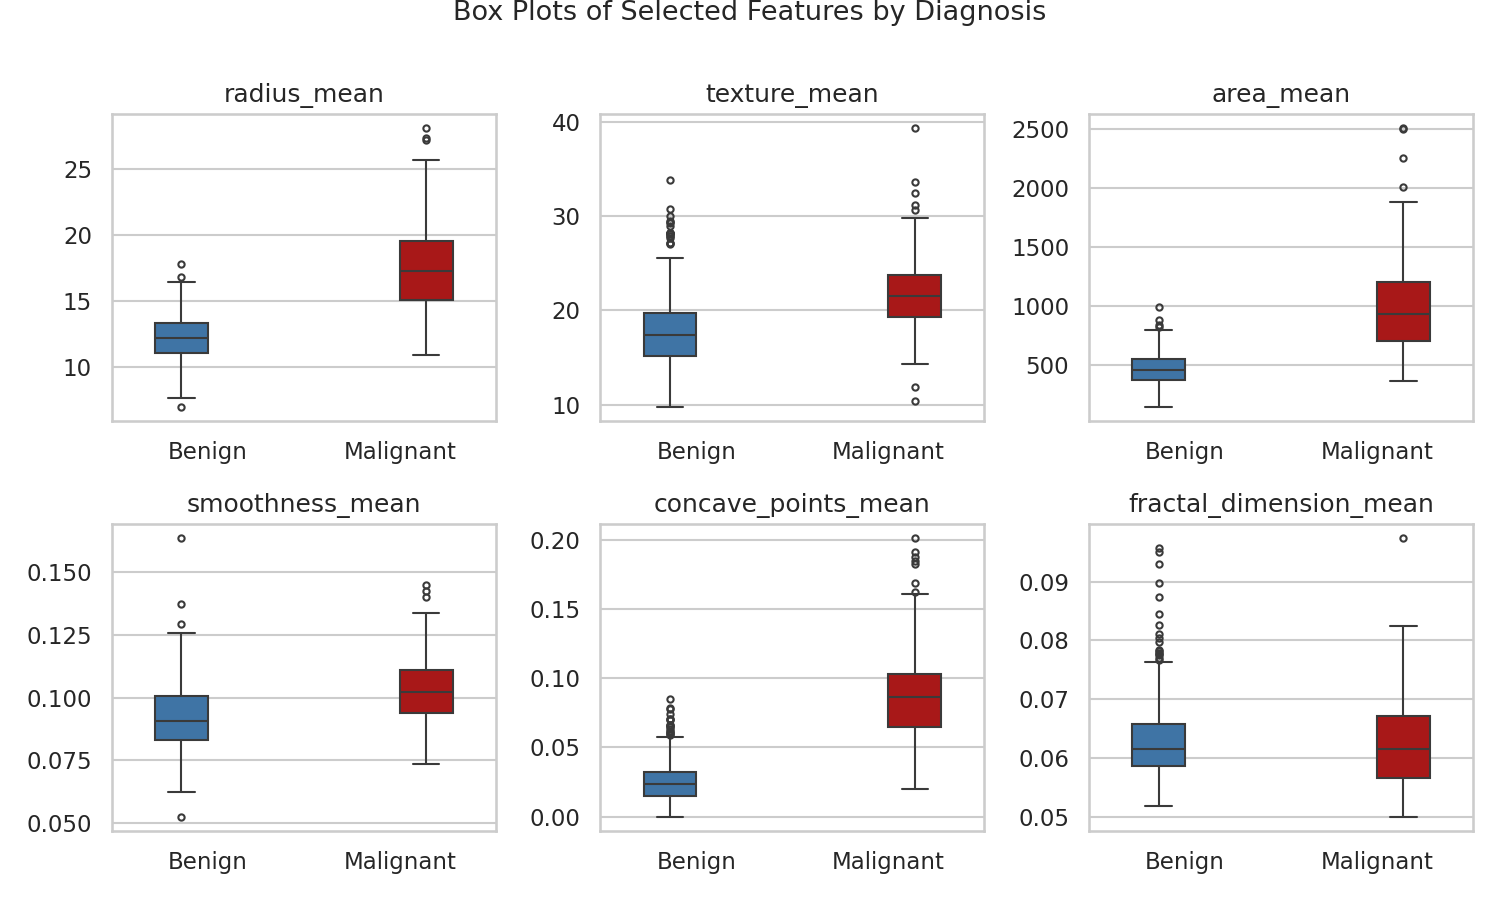

In [12]:
cols = ["radius_mean", "texture_mean", "area_mean", "smoothness_mean", "concave_points_mean", "fractal_dimension_mean"]
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x="diagnosis", y=col, hue="diagnosis", order=["Benign", "Malignant"],
                palette=PAL, legend=False, ax=ax, width=0.55, fliersize=3)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Box Plots of Selected Features by Diagnosis", y=1.0, fontsize=13)
plt.tight_layout()
plt.savefig("charts/04_boxplots_by_diagnosis.png", dpi=150)
plt.show()

### Chart 5: Correlation heatmap

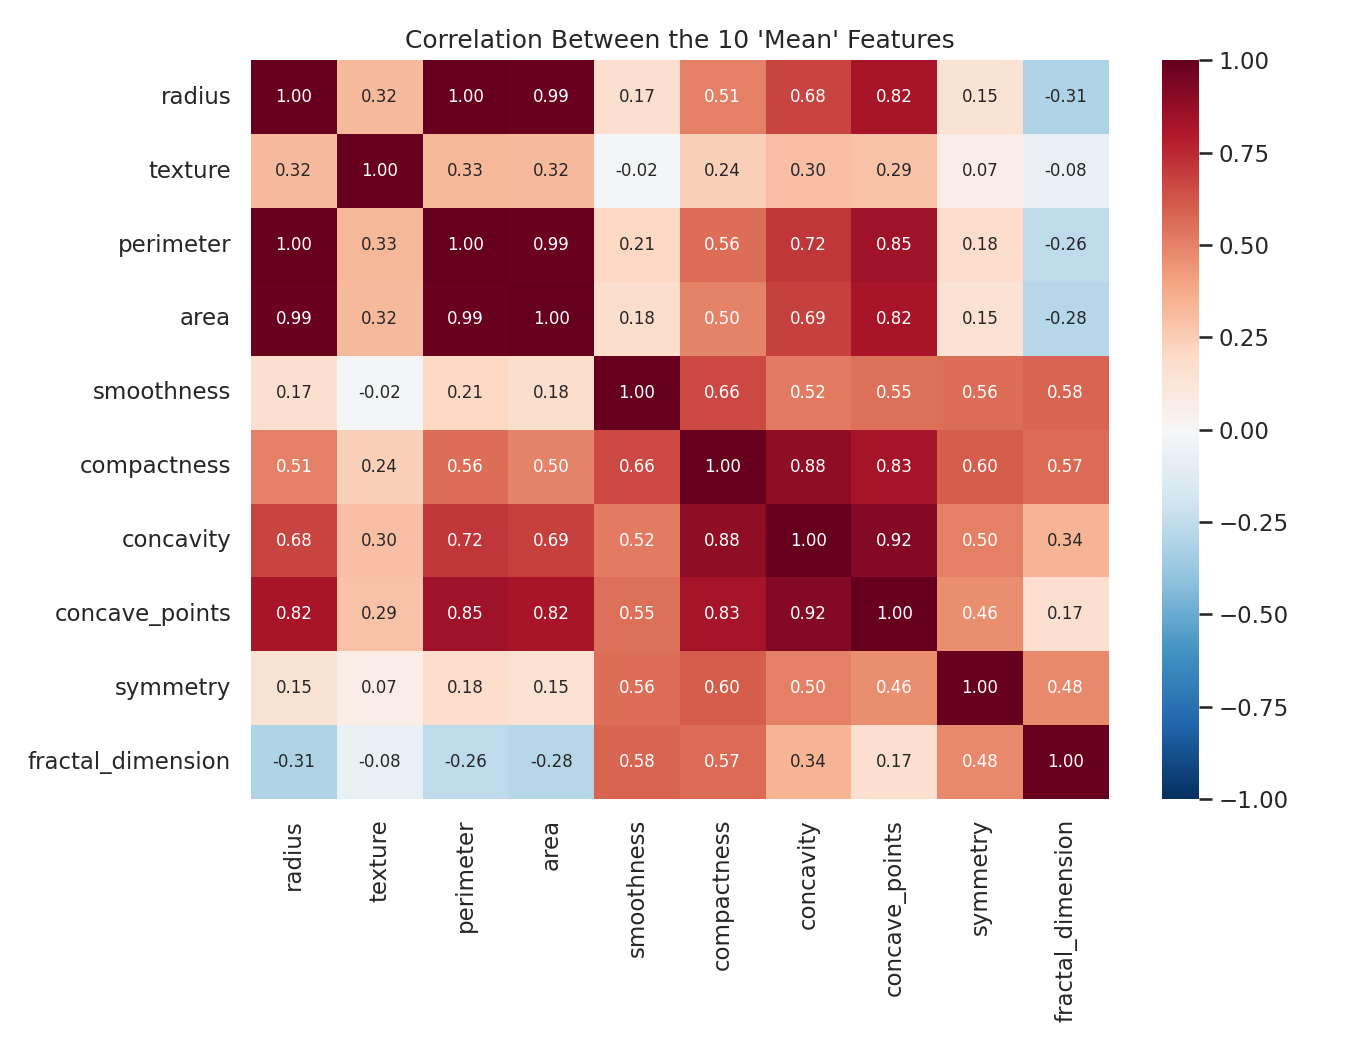

In [13]:
fig, ax = plt.subplots(figsize=(9, 7))
labels = [c.replace("_mean", "") for c in mean_cols]
sns.heatmap(corr.set_axis(labels, axis=0).set_axis(labels, axis=1), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation Between the 10 'Mean' Features")
plt.tight_layout()
plt.savefig("charts/05_correlation_heatmap.png", dpi=150)
plt.show()

### Chart 6: Relationship between two key features (scatter plot)

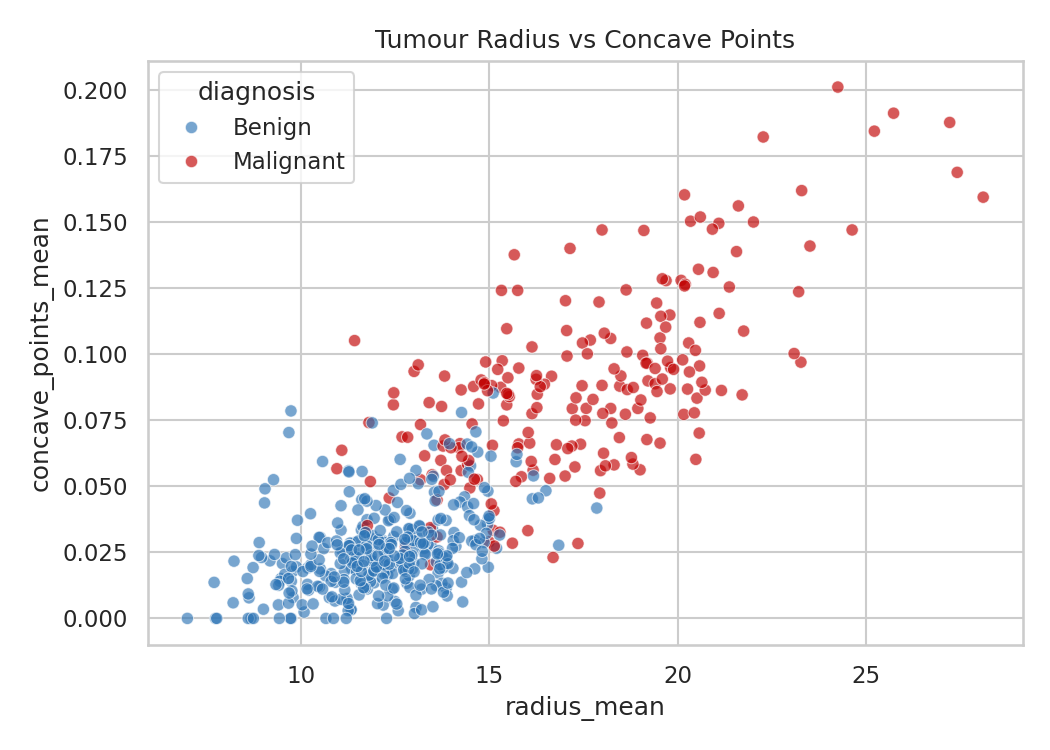

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="radius_mean", y="concave_points_mean", hue="diagnosis",
                hue_order=["Benign", "Malignant"], palette=PAL, alpha=0.65, s=35, ax=ax)
ax.set_title("Tumour Radius vs Concave Points")
ax.set_xlabel("radius_mean")
ax.set_ylabel("concave_points_mean")
plt.tight_layout()
plt.savefig("charts/06_scatter_radius_concave.png", dpi=150)
plt.show()

### Chart 7: Which features separate the two groups best? (bar chart of effect sizes)

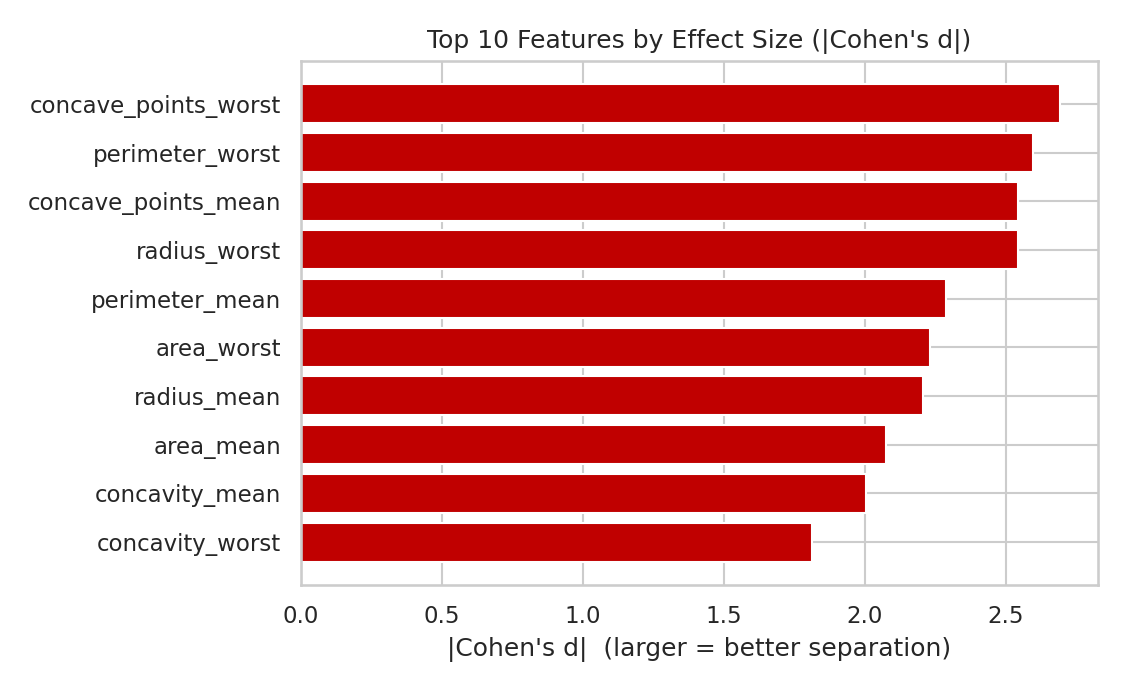

In [15]:
top = tests.head(10).sort_values("abs_d")
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top.index, top["abs_d"], color="#C00000")
ax.set_title("Top 10 Features by Effect Size (|Cohen's d|)")
ax.set_xlabel("|Cohen's d|  (larger = better separation)")
plt.tight_layout()
plt.savefig("charts/07_top_effect_sizes.png", dpi=150)
plt.show()

## Part E: Supporting analysis: how much signal do the features carry?
A simple, standardised logistic regression is evaluated with 5-fold cross-validation. Features are ranked by effect size inside each training fold, so the test data never influences the ranking. This is only a check of how separable the groups are, not a diagnostic tool.

Cross-validated accuracy by number of features used:
  top  1 feature(s): 90.7%  (+/- 1.2)
  top  2 feature(s): 93.2%  (+/- 2.4)
  top  3 feature(s): 93.2%  (+/- 2.0)
  top  5 feature(s): 94.2%  (+/- 1.6)
  top 10 feature(s): 95.1%  (+/- 1.6)
  top 20 feature(s): 97.5%  (+/- 1.3)
  top 30 feature(s): 97.4%  (+/- 1.7)

Highest accuracy: 98.1% with 26 features
Majority-class baseline (always predict benign): 62.7%


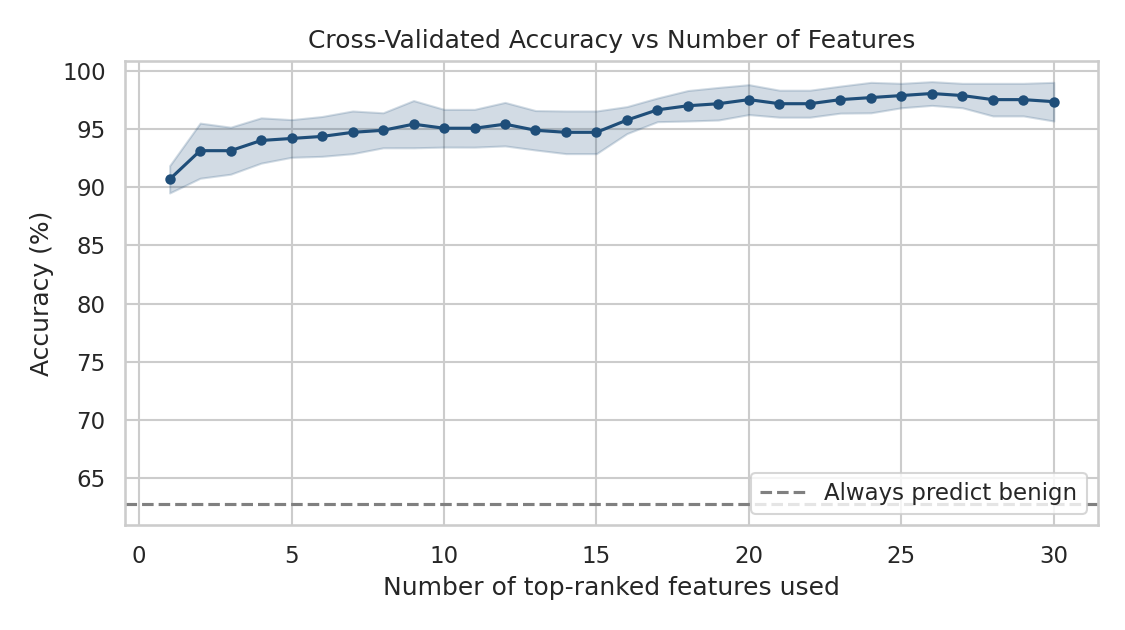

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = list(range(1, 31))
acc = {k: [] for k in ks}

for train_idx, test_idx in skf.split(X, y):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_te, y_te = X.iloc[test_idx], y.iloc[test_idx]
    order = cohens_d(X_tr, y_tr).abs().sort_values(ascending=False).index
    for k in ks:
        cols_k = list(order[:k])
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        model.fit(X_tr[cols_k], y_tr)
        acc[k].append(model.score(X_te[cols_k], y_te))

mean_acc = np.array([np.mean(acc[k]) for k in ks])
std_acc = np.array([np.std(acc[k]) for k in ks])
print("Cross-validated accuracy by number of features used:")
for k in [1, 2, 3, 5, 10, 20, 30]:
    print(f"  top {k:>2} feature(s): {mean_acc[k - 1] * 100:.1f}%  (+/- {std_acc[k - 1] * 100:.1f})")
best_k = int(np.argmax(mean_acc)) + 1
print(f"\nHighest accuracy: {mean_acc.max() * 100:.1f}% with {best_k} features")
print(f"Majority-class baseline (always predict benign): {(1 - y.mean()) * 100:.1f}%")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(ks, mean_acc * 100, marker="o", markersize=4, color="#1F4E79")
ax.fill_between(ks, (mean_acc - std_acc) * 100, (mean_acc + std_acc) * 100, alpha=0.2, color="#1F4E79")
ax.axhline((1 - y.mean()) * 100, color="grey", linestyle="--", label="Always predict benign")
ax.set_title("Cross-Validated Accuracy vs Number of Features")
ax.set_xlabel("Number of top-ranked features used")
ax.set_ylabel("Accuracy (%)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("charts/08_accuracy_vs_features.png", dpi=150)
plt.show()

## Part F: Summary of findings

In [17]:
mal = df[df["diagnosis"] == "Malignant"]
ben = df[df["diagnosis"] == "Benign"]
print(f"1. Dataset            : {len(df)} cases, {len(feature_cols)} features, no missing values, no duplicates")
print(f"2. Class balance      : {len(ben)} benign ({len(ben) / len(df) * 100:.1f}%) vs {len(mal)} malignant ({len(mal) / len(df) * 100:.1f}%)")
print(f"3. Mean radius        : malignant {mal['radius_mean'].mean():.2f} vs benign {ben['radius_mean'].mean():.2f}")
print(f"4. Mean area          : malignant {mal['area_mean'].mean():.0f} vs benign {ben['area_mean'].mean():.0f}")
print(f"5. Best separators    : {', '.join(tests.index[:3])}")
print(f"6. Weakest separator  : {tests.index[-1]} (d = {tests['cohens_d'].iloc[-1]:.2f})")
print(f"7. Redundant features : {len(strong)} pairs of mean features with |r| >= 0.85")
print(f"8. Predictive signal  : {mean_acc[2] * 100:.1f}% accuracy with only 3 features, {mean_acc.max() * 100:.1f}% at best")

1. Dataset            : 569 cases, 30 features, no missing values, no duplicates
2. Class balance      : 357 benign (62.7%) vs 212 malignant (37.3%)
3. Mean radius        : malignant 17.46 vs benign 12.15
4. Mean area          : malignant 978 vs benign 463
5. Best separators    : concave_points_worst, perimeter_worst, concave_points_mean
6. Weakest separator  : symmetry_se (d = -0.01)
7. Redundant features : 6 pairs of mean features with |r| >= 0.85
8. Predictive signal  : 93.2% accuracy with only 3 features, 98.1% at best
